In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.model_selection import train_test_split

In [3]:
DATA_PATH = './dataset/'
img_row, img_col = 102, 136
x, y = [], []
classes = os.listdir(DATA_PATH)
print(classes)
counter = 0

['Boot', 'Sandal', 'Shoe']


In [4]:
for class_path in classes:
    for img_path in os.listdir(f"{DATA_PATH}{class_path}"):
        path = f"{DATA_PATH}{class_path}/{img_path}"
        label = counter
        img = tf.keras.preprocessing.image.load_img(path, target_size=(img_row, img_col))
        img = tf.keras.preprocessing.image.img_to_array(img)
        x.append(img)
        y.append(label)
    counter += 1

x = np.array(x)
y = np.array(y)
x = x.astype('float32') / 255.0

In [5]:
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, random_state=42
)
x_test, x_val, y_test, y_val = train_test_split(
    x_temp, y_temp, test_size=0.5, random_state=42
)
y_train = keras.utils.to_categorical(y_train)
y_test = keras.utils.to_categorical(y_test)
y_val = keras.utils.to_categorical(y_val)

In [6]:
import keras.layers

model = keras.Sequential()

model.add(keras.layers.Conv2D(6, (6,6), activation="relu", input_shape=(img_row, img_col, 3)))
model.add(keras.layers.AveragePooling2D((2,2), 2))
model.add(keras.layers.Conv2D(16, (6,6), activation="relu"))
model.add(keras.layers.AveragePooling2D((2,2), 2))

model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(120, activation="relu"))
model.add(keras.layers.Dense(60, activation="relu"))
model.add(keras.layers.Dense(3, activation="softmax"))

model.summary()

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 97, 131, 6)     │           654 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 48, 65, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 43, 60, 16)     │         3,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 21, 30, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10080)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     1,209,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 60)             │         7,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           183 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,221,289 (4.66 MB)

 Trainable params: 1,221,289 (4.66 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=10, batch_size=120,
    validation_data=(x_val, y_val)
)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 221ms/step - accuracy: 0.6308 - loss: 0.8760 - val_accuracy: 0.8600 - val_loss: 0.3919
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 188ms/step - accuracy: 0.7967 - loss: 0.4528 - val_accuracy: 0.9000 - val_loss: 0.2368
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step - accuracy: 0.8242 - loss: 0.4011 - val_accuracy: 0.9267 - val_loss: 0.2375
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 164ms/step - accuracy: 0.8950 - loss: 0.3002 - val_accuracy: 0.9400 - val_loss: 0.2051
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 199ms/step - accuracy: 0.9233 - loss: 0.2283 - val_accuracy: 0.9400 - val_loss: 0.1654
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 167ms/step - accuracy: 0.9342 - loss: 0.1969 - val_accuracy: 0.9667 - val_loss: 0.1459
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.9483 - loss: 0.1680 - val_accuracy: 0.9600 - val_loss: 0.1610
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step - accuracy: 0.9500 - loss: 0.1516 - val_accuracy: 0.

In [8]:
model.evaluate(x_test, y_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9333 - loss: 0.2319


[0.23194468021392822, 0.9333333373069763]

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


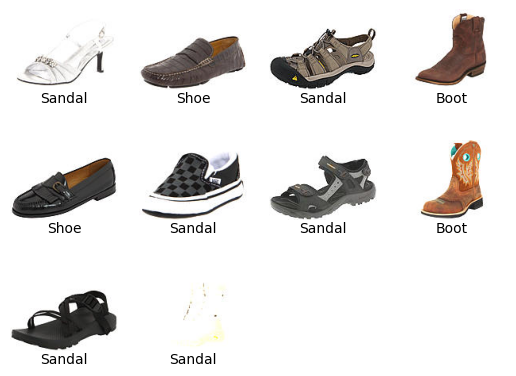

In [11]:
prediction = model.predict(x_test)
predicted_label = np.argmax(prediction, axis=1)

for i in range(10):
    plt.subplot(3, 4, i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.axis('off')
    plt.text(
        0.5, -0.15,
        classes[predicted_label[i]], ha='center',
        transform=plt.gca().transAxes
    )

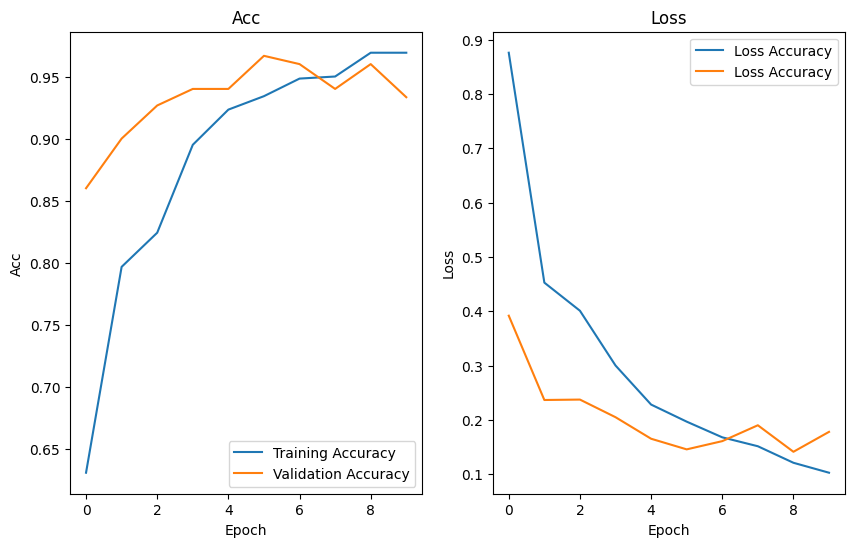

In [13]:
plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Acc")
plt.xlabel("Epoch")
plt.ylabel("Acc")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss Accuracy')
plt.plot(history.history['val_loss'], label='Loss Accuracy')
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()